In [1]:
import pandas as pd
import numpy as np

# Carregar a base de dados
df = pd.read_csv("../data/WineQT.csv")

# Mostrar as primeiras linhas
display(df.head())


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


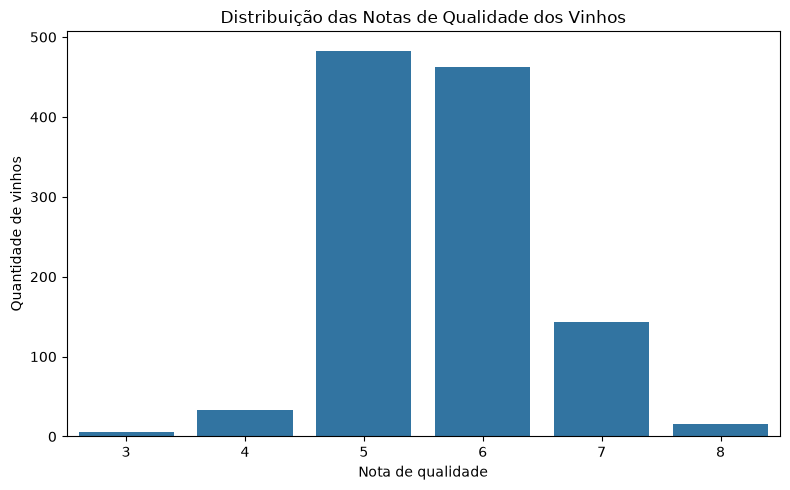

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define o tamanho da figura para facilitar a leitura
plt.figure(figsize=(8, 5))

# Cria um gráfico de barras com a frequência de cada nota
sns.countplot(data=df, x="quality")

# Adiciona um título e identifica os eixos
plt.title("Distribuição das Notas de Qualidade dos Vinhos")
plt.xlabel("Nota de qualidade")
plt.ylabel("Quantidade de vinhos")

# Ajusta os espaçamentos e exibe o gráfico
plt.tight_layout()
plt.show()


### Análise da distribuição das notas de qualidade

Nesta etapa, analisamos a frequência de cada nota de qualidade presente na base de dados. Essa verificação permite compreender como as observações estão distribuídas entre as diferentes notas e identificar possíveis concentrações ou desequilíbrios que possam influenciar a construção e a avaliação do modelo de classificação.

In [3]:
# Conta quantos vinhos existem em cada nota de qualidade
frequencia_qualidade = df["quality"].value_counts().sort_index()

# Calcula a porcentagem correspondente a cada nota
percentual_qualidade = (
    df["quality"].value_counts(normalize=True).sort_index() * 100
)

# Organiza os resultados em uma tabela
distribuicao_qualidade = pd.DataFrame({
    "Quantidade de vinhos": frequencia_qualidade,
    "Percentual (%)": percentual_qualidade.round(2)
})

# Exibe a tabela
display(distribuicao_qualidade)

,Quantidade de vinhos,Percentual (%)
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40


### Análise da distribuição das notas de qualidade

A distribuição da variável `quality` apresenta concentração nas notas 5 e 6, que correspondem, respectivamente, a 42,26% e 40,42% das observações. Em conjunto, essas duas categorias representam 82,68% da base de dados.

As notas extremas apresentam baixa frequência: a nota 3 representa 0,52% das observações, enquanto a nota 8 corresponde a 1,40%. Esse cenário evidencia um desequilíbrio na distribuição das classes, que deve ser considerado na construção e na avaliação do modelo de classificação.

Essa análise é relevante porque a regressão logística pode apresentar maior facilidade para classificar corretamente as categorias mais frequentes. Portanto, além da acurácia, será importante avaliar métricas como precisão, recall e F1-score por classe, para compreender melhor o desempenho do modelo.


In [4]:
# Verifica as colunas existentes na base de dados
print(df.columns.tolist())

# Verifica se a variável de classificação já foi criada
if "quality_class" in df.columns:
    print("\nDistribuição das classes:")
    print(df["quality_class"].value_counts().sort_index())
else:
    print("\nA variável quality_class ainda não existe no DataFrame.")

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

A variável quality_class ainda não existe no DataFrame.


In [5]:
# Cria uma nova variável para classificar a qualidade dos vinhos
# As regras são baseadas na nota original da variável quality

df["quality_class"] = pd.cut(
    df["quality"],
    bins=[-float("inf"), 4, 6, float("inf")],
    labels=["baixa", "media", "alta"]
)

# Exibe as primeiras linhas para conferir a nova variável
display(df[["quality", "quality_class"]].head(10))

,quality,quality_class
0,5,media
1,5,media
2,5,media
3,6,media
4,5,media
5,5,media
6,5,media
7,7,alta
8,7,alta
9,5,media


In [6]:
# Conta quantos vinhos pertencem a cada classe
quantidade_classes = df["quality_class"].value_counts().sort_index()

# Calcula o percentual de cada classe
percentual_classes = (
    df["quality_class"].value_counts(normalize=True).sort_index() * 100
)

# Organiza os resultados em uma tabela
distribuicao_classes = pd.DataFrame({
    "Quantidade de vinhos": quantidade_classes,
    "Percentual (%)": percentual_classes.round(2)
})

# Exibe a distribuição das classes
display(distribuicao_classes)


,Quantidade de vinhos,Percentual (%)
quality_class,,
baixa,39,3.41
media,945,82.68
alta,159,13.91


### Criação da variável-alvo `quality_class`

Para a construção do modelo de classificação, foi criada a variável `quality_class` a partir da variável original `quality`. As notas foram agrupadas em três categorias: baixa qualidade (notas até 4), média qualidade (notas 5 e 6) e alta qualidade (notas 7 e 8).

O agrupamento foi adotado para transformar as notas numéricas em categorias que possam ser utilizadas como variável-alvo da regressão logística. Após essa transformação, a distribuição das classes será analisada para verificar a representatividade de cada categoria e identificar possíveis desequilíbrios que possam afetar o treinamento e a avaliação do modelo.


### Análise do balanceamento da variável-alvo

Após a criação da variável `quality_class`, a base apresentou 1.143 observações distribuídas em três categorias: baixa, média e alta qualidade. A classe média concentra 82,68% dos registros, enquanto as classes alta e baixa representam 13,91% e 3,41%, respectivamente.

Essa distribuição evidencia um desequilíbrio entre as classes, especialmente pela baixa representatividade dos vinhos classificados como de baixa qualidade. Esse aspecto será considerado na modelagem e na avaliação dos resultados, uma vez que o modelo pode apresentar desempenhos diferentes para cada categoria.

Para avaliar adequadamente a capacidade de classificação, serão consideradas métricas como precisão, recall e F1-score por classe, além da acurácia global.


In [7]:
# Define as variáveis de entrada (características químicas)
# Excluímos quality, pois ela originou a variável-alvo,
# e Id, pois é apenas um identificador.

X = df.drop(columns=["quality", "quality_class", "Id"])

# Define a variável que o modelo deverá prever
y = df["quality_class"]

# Confere as dimensões dos dados
print("Dimensões das variáveis de entrada:", X.shape)
print("Quantidade de observações na variável-alvo:", y.shape[0])

# Confere as colunas utilizadas pelo modelo
print("\nVariáveis de entrada:")
print(X.columns.tolist())

Dimensões das variáveis de entrada: (1143, 11)
Quantidade de observações na variável-alvo: 1143

Variáveis de entrada:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [8]:
from sklearn.model_selection import train_test_split

# Separa 80% dos dados para treinamento e 20% para teste
# stratify=y preserva aproximadamente a proporção das classes
# random_state=42 permite reproduzir a mesma divisão

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Exibe a quantidade de observações em cada conjunto
print("Treinamento:", X_train.shape[0], "observações")
print("Teste:", X_test.shape[0], "observações")

# Confere a distribuição das classes no conjunto de teste
print("\nDistribuição das classes no teste:")
print(y_test.value_counts())

Treinamento: 914 observações
Teste: 229 observações

Distribuição das classes no teste:
quality_class
media    189
alta      32
baixa      8
Name: count, dtype: int64


In [9]:
# Importa as ferramentas necessárias para o modelo
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Cria um pipeline com padronização e regressão logística
modelo = Pipeline([
    ("padronizacao", StandardScaler()),
    ("regressao_logistica", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Pipeline criado com sucesso.")

Pipeline criado com sucesso.


In [10]:
# Treina o pipeline usando somente os dados de treinamento
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [11]:
# Utiliza o modelo treinado para prever a qualidade dos vinhos do teste
y_pred = modelo.predict(X_test)

# Exibe algumas previsões e compara com os valores reais
comparacao = pd.DataFrame({
    "Qualidade real": y_test,
    "Qualidade prevista": y_pred
})

display(comparacao.head(10))

,Qualidade real,Qualidade prevista
374,media,media
846,media,media
293,media,media
729,alta,alta
181,media,media
1138,media,media
316,media,media
173,media,media
1051,media,media
166,media,media


In [12]:
# Importa as métricas para avaliar o modelo
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calcula a acurácia geral
acuracia = accuracy_score(y_test, y_pred)

print(f"Acurácia do modelo: {acuracia:.2%}")

# Exibe precisão, recall e F1-score para cada classe
print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred,
    labels=["baixa", "media", "alta"],
    zero_division=0
))

Acurácia do modelo: 82.10%

Relatório de classificação:
              precision    recall  f1-score   support

       baixa       0.00      0.00      0.00         8
       media       0.86      0.94      0.90       189
        alta       0.48      0.31      0.38        32

    accuracy                           0.82       229
   macro avg       0.44      0.42      0.42       229
weighted avg       0.77      0.82      0.79       229



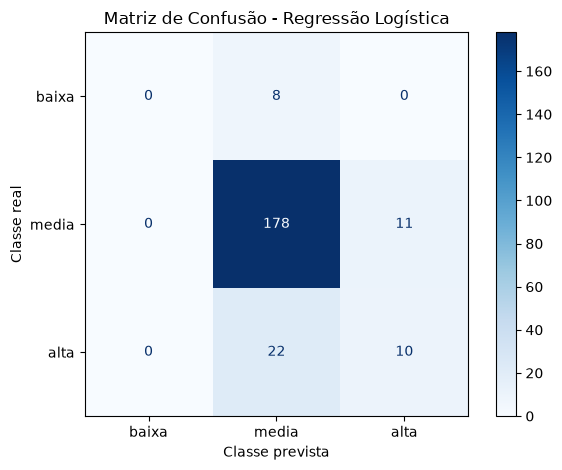

In [13]:
# Calcula a matriz de confusão na ordem baixa, media e alta
ordem_classes = ["baixa", "media", "alta"]

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=ordem_classes
)

# Cria o gráfico da matriz de confusão
grafico = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=ordem_classes
)

grafico.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - Regressão Logística")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

### Avaliação inicial da regressão logística

A regressão logística obteve acurácia de aproximadamente 82,1% no conjunto de teste, composto por 229 observações. Entretanto, a análise das métricas por classe revelou diferenças importantes no desempenho do modelo.

A classe média apresentou F1-score de 0,90 e recall de 0,94, indicando bom desempenho na identificação dessa categoria. Por outro lado, a classe alta apresentou F1-score de 0,38 e recall de 0,31. Para a classe baixa, as métricas de precisão, recall e F1-score foram iguais a zero.

O F1-score macro de 0,42 evidencia que o desempenho do modelo não é equilibrado entre as categorias. Esses resultados devem ser interpretados considerando o desequilíbrio da variável-alvo, especialmente a baixa representatividade da classe baixa.

Assim, embora a acurácia geral seja relativamente alta, ela não representa, isoladamente, a capacidade do modelo de reconhecer adequadamente todas as classes de qualidade.


In [14]:
# Cria uma nova regressão logística com pesos ajustados por classe
modelo_balanceado = Pipeline([
    ("padronizacao", StandardScaler()),
    ("regressao_logistica", LogisticRegression(
        max_iter=2000,
        random_state=42,
        class_weight="balanced"
    ))
])

# Treina o novo modelo com os mesmos dados de treinamento
modelo_balanceado.fit(X_train, y_train)

# Faz previsões nos mesmos dados de teste
y_pred_balanceado = modelo_balanceado.predict(X_test)

# Avalia o desempenho por classe
print("Relatório de classificação — modelo balanceado:")
print(classification_report(
    y_test,
    y_pred_balanceado,
    labels=["baixa", "media", "alta"],
    zero_division=0
))

Relatório de classificação — modelo balanceado:
              precision    recall  f1-score   support

       baixa       0.10      0.75      0.18         8
       media       0.94      0.48      0.63       189
        alta       0.33      0.78      0.47        32

    accuracy                           0.53       229
   macro avg       0.46      0.67      0.43       229
weighted avg       0.82      0.53      0.59       229



### Comparação entre a regressão logística original e a balanceada

Foi realizada uma comparação entre a regressão logística original e uma segunda versão com o parâmetro `class_weight="balanced"`, que atribui pesos maiores às classes menos representadas durante o treinamento.

O modelo original apresentou acurácia de 82,1%, mas não identificou corretamente nenhum vinho da classe baixa. Já o modelo balanceado apresentou acurácia de aproximadamente 53,3%, com aumento do recall das classes baixa, de 0,00 para 0,75, e alta, de 0,31 para 0,78.

Em contrapartida, o recall da classe média diminuiu de 0,94 para 0,48. O F1-score macro permaneceu praticamente estável, passando de aproximadamente 0,42 para 0,43.

Os resultados demonstram uma relação de compromisso entre a acurácia global e a capacidade de identificar as classes minoritárias. Portanto, a escolha do modelo deverá considerar o objetivo da classificação e o desempenho individual em cada classe, não apenas a acurácia.



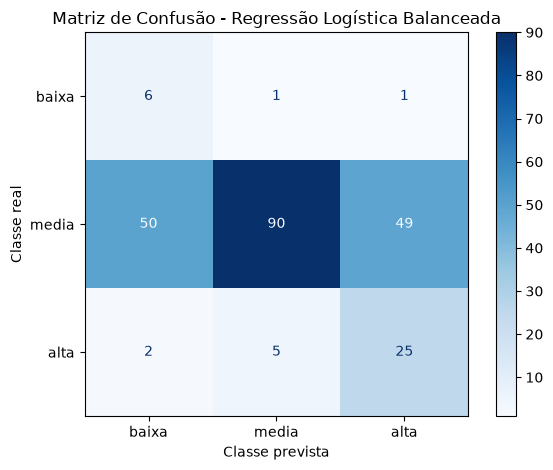

In [15]:
# Define a ordem das classes para manter a comparação consistente
ordem_classes = ["baixa", "media", "alta"]

# Calcula a matriz de confusão do modelo balanceado
matriz_balanceada = confusion_matrix(
    y_test,
    y_pred_balanceado,
    labels=ordem_classes
)

# Exibe a matriz como um gráfico
grafico = ConfusionMatrixDisplay(
    confusion_matrix=matriz_balanceada,
    display_labels=ordem_classes
)

grafico.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - Regressão Logística Balanceada")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

In [16]:
# Importa as ferramentas para comparar configurações
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define diferentes pesos para testar
pesos_classes = [
    None,
    "balanced",
    {"baixa": 2, "media": 1, "alta": 1},
    {"baixa": 3, "media": 1, "alta": 1.5}
]

# Define a validação cruzada estratificada com 5 partes
validacao = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define as configurações que serão testadas
parametros = {
    "regressao_logistica__C": [0.1, 1, 10],
    "regressao_logistica__class_weight": pesos_classes
}

# Procura a configuração com melhor F1-score macro médio
busca_modelo = GridSearchCV(
    estimator=modelo,
    param_grid=parametros,
    scoring="f1_macro",
    cv=validacao,
    n_jobs=-1,
    refit=True
)

# Executa a busca somente nos dados de treinamento
busca_modelo.fit(X_train, y_train)

# Exibe a melhor configuração encontrada
print("Melhores parâmetros:")
print(busca_modelo.best_params_)

print("\nF1-score macro médio na validação cruzada:")
print(round(busca_modelo.best_score_, 3))

Melhores parâmetros:
{'regressao_logistica__C': 0.1, 'regressao_logistica__class_weight': {'baixa': 3, 'media': 1, 'alta': 1.5}}

F1-score macro médio na validação cruzada:
0.485


Acurácia do modelo otimizado:
82.97%

Relatório de classificação:
              precision    recall  f1-score   support

       baixa       0.33      0.12      0.18         8
       media       0.89      0.91      0.90       189
        alta       0.53      0.53      0.53        32

    accuracy                           0.83       229
   macro avg       0.58      0.52      0.54       229
weighted avg       0.82      0.83      0.82       229



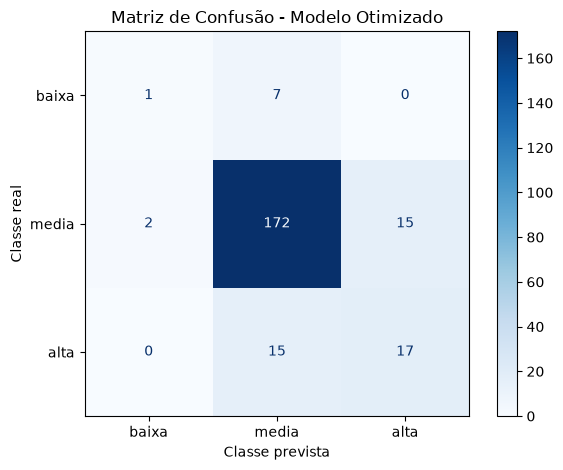

In [17]:
# Utiliza a melhor configuração para prever os dados de teste
modelo_otimizado = busca_modelo.best_estimator_
y_pred_otimizado = modelo_otimizado.predict(X_test)

# Avalia o modelo escolhido no conjunto de teste
print("Acurácia do modelo otimizado:")
print(f"{accuracy_score(y_test, y_pred_otimizado):.2%}")

print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred_otimizado,
    labels=["baixa", "media", "alta"],
    zero_division=0
))

# Exibe a matriz de confusão
matriz_otimizada = confusion_matrix(
    y_test,
    y_pred_otimizado,
    labels=["baixa", "media", "alta"]
)

grafico = ConfusionMatrixDisplay(
    confusion_matrix=matriz_otimizada,
    display_labels=["baixa", "media", "alta"]
)

grafico.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - Modelo Otimizado")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

### Comparação e seleção do modelo de regressão logística

Foram avaliadas três configurações de regressão logística: o modelo original, o modelo com balanceamento de classes e o modelo otimizado por validação cruzada com busca em grade (*GridSearchCV*), utilizando o F1-score macro como critério de seleção dos hiperparâmetros.

O modelo original obteve acurácia de 82,10% e F1-score macro de aproximadamente 0,42. O modelo balanceado apresentou F1-score macro de aproximadamente 0,43, mas sua acurácia foi reduzida para 53,00%. Por sua vez, o modelo otimizado alcançou acurácia de 82,97% e F1-score macro de 0,54, além de melhorar o F1-score da classe `alta` para 0,53.

Com base nesses resultados, o modelo otimizado foi selecionado como candidato principal, pois apresentou o melhor equilíbrio geral entre as classes segundo o F1-score macro, mantendo uma acurácia elevada. Apesar disso, o desempenho da classe `baixa` permaneceu limitado, com recall de 0,12. Essa limitação está relacionada, entre outros fatores, à baixa representatividade dessa classe na base de dados.

Assim, os resultados indicam que a regressão logística apresenta desempenho satisfatório para a classe `media`, mas ainda enfrenta dificuldades para identificar consistentemente as classes minoritárias. As conclusões devem ser interpretadas considerando a dimensão reduzida da classe `baixa` no conjunto de teste e o fato de a avaliação final ter sido realizada em uma única divisão treino-teste.